In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy import stats 

In [2]:
data = pd.read_csv('Documents/class material/data analytics with python/project2/1757674790_dataset_cep_02/marketing_data.csv')

In [3]:
data.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country
0,1826,1970,Graduation,Divorced,"$84,835.00",0,0,6/16/14,0,189,...,6,1,0,0,0,0,0,1,0,SP
1,1,1961,Graduation,Single,"$57,091.00",0,0,6/15/14,0,464,...,7,5,0,0,0,0,1,1,0,CA
2,10476,1958,Graduation,Married,"$67,267.00",0,1,5/13/14,0,134,...,5,2,0,0,0,0,0,0,0,US
3,1386,1967,Graduation,Together,"$32,474.00",1,1,5/11/14,0,10,...,2,7,0,0,0,0,0,0,0,AUS
4,5371,1989,Graduation,Single,"$21,474.00",1,0,4/8/14,0,6,...,2,7,1,0,0,0,0,1,0,SP


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID                   2240 non-null   int64 
 1   Year_Birth           2240 non-null   int64 
 2   Education            2240 non-null   object
 3   Marital_Status       2240 non-null   object
 4    Income              2216 non-null   object
 5   Kidhome              2240 non-null   int64 
 6   Teenhome             2240 non-null   int64 
 7   Dt_Customer          2240 non-null   object
 8   Recency              2240 non-null   int64 
 9   MntWines             2240 non-null   int64 
 10  MntFruits            2240 non-null   int64 
 11  MntMeatProducts      2240 non-null   int64 
 12  MntFishProducts      2240 non-null   int64 
 13  MntSweetProducts     2240 non-null   int64 
 14  MntGoldProds         2240 non-null   int64 
 15  NumDealsPurchases    2240 non-null   int64 
 16  NumWeb

In [5]:
data.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
 Income                24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64

In [6]:
data.describe()

,ID,Year_Birth,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain
count,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,27.062946,...,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.149107,0.009375
std,3246.662198,11.984069,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,41.280498,...,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.356274,0.096391
min,0.000000,1893.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,1.000000,...,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5458.500000,1970.000000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,8.000000,...,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8427.750000,1977.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,33.000000,...,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,11191.000000,1996.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,263.000000,...,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [7]:
#2. Investigate Variables
  #• Check variables like Dt_Customer and Income to ensure they are imported correctly

# removing space around income column

data.rename(columns={" Income ":"Income"}, inplace=True)

#Convert the income column to a float by removing '$' and ',' and using astype('float')

data["Income"] =(
    data["Income"]
    .str.replace("$","",regex=False)
    .str.replace(",","",regex=False)
    .astype(float)
)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 28 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [9]:
# Convert the Dt_Customer column to a datetime object using pd.to_datetime()

data["Dt_Customer"]=pd.to_datetime(data["Dt_Customer"],format="%m/%d/%y")

In [10]:
#3. Missing Value Imputation
  #• Check for missing values using data.isnull().sum()

data.isnull().sum()

ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Response                0
Complain                0
Country                 0
dtype: int64

In [11]:
#Clean the marital_status and education categories (e.g., combining similar categories)
  # clean the marital_status
data["Marital_Status"]=data["Marital_Status"].replace({
    "Alone": "Single",
    "YOLO": "Single",
    "Absurd": "Single"
})

#Impute missing income:
data["Income"]=data.groupby(["Education", "Marital_Status"])["Income"].transform(lambda x:x.fillna(x.mean()))
data["Income"]=data["Income"].fillna(data["Income"].mean())

In [12]:
#4. Create Variables
  #• Calculate the age of customers based on year_birth

from datetime import datetime
data["Age"]=datetime.now().year-data["Year_Birth"]

In [13]:
#• Calculate spending as the sum of spending columns (mntwines,mntfruits, etc.)

data["Spending"] = (
    data["MntWines"]
    + data["MntFruits"]
    + data["MntMeatProducts"]
    + data["MntFishProducts"]
    + data["MntSweetProducts"]
    + data["MntGoldProds"]
)

In [14]:
#• Calculate children_count as the sum of kidhome and teenhome.
data["Children_Count"] = data["Kidhome"] + data["Teenhome"]

#• Create a binary variable has_children indicating if a customer has children

data["Has_Children"] = (data["Children_Count"] > 0).astype(int)

In [15]:
#• Derive total_purchases from the sum of purchase columns

data["Total_Purchases"]=(
    data["NumDealsPurchases"]
    + data["NumWebPurchases"]
    + data["NumCatalogPurchases"]
    + data["NumStorePurchases"]
)


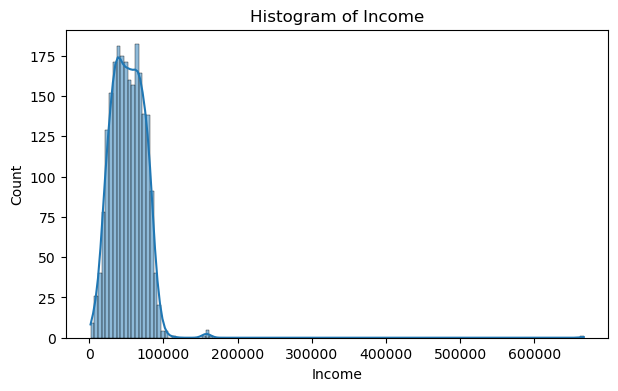

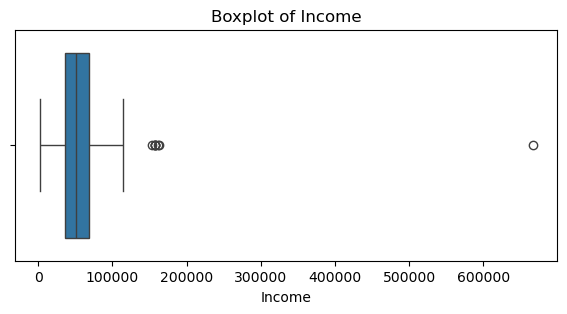

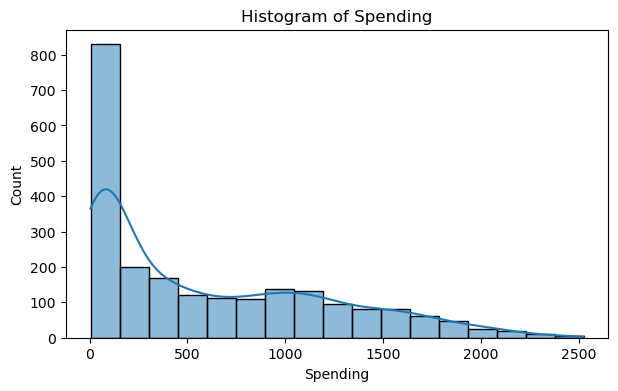

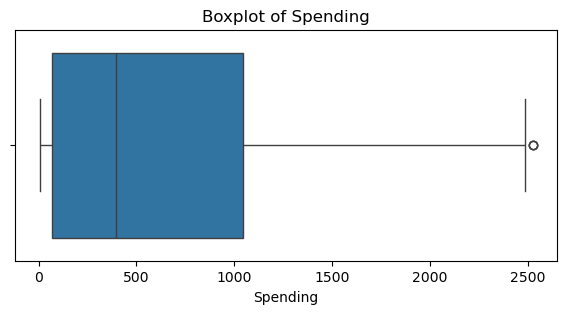

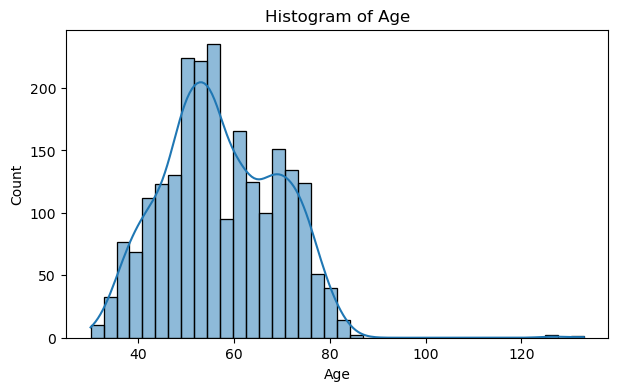

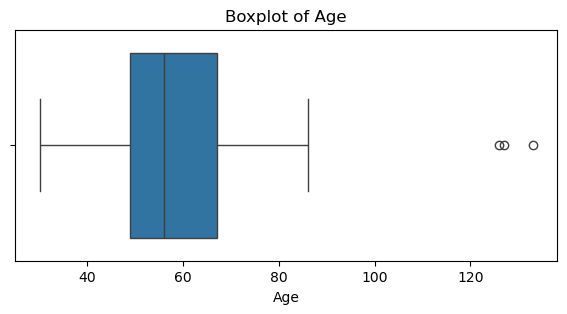

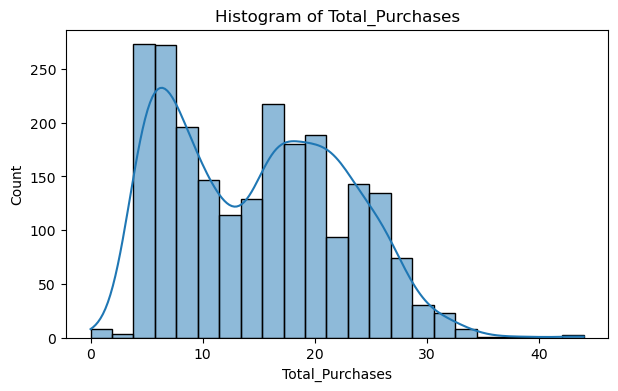

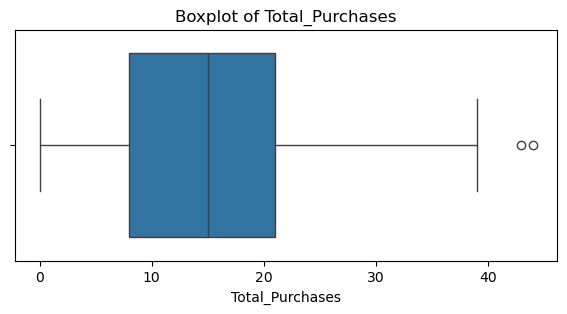

In [16]:
#5. Box Plots and Histograms
 #• Plot box plots and histograms for numerical variables (income,spending, age, total_purchases) to understand their distributions and
    #identify outliers
num_cols = ["Income", "Spending", "Age", "Total_Purchases"]

for col in num_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(data[col], kde=True)
    plt.title(f"Histogram of {col}")
    plt.show()

    plt.figure(figsize=(7,3))
    sns.boxplot(x=data[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

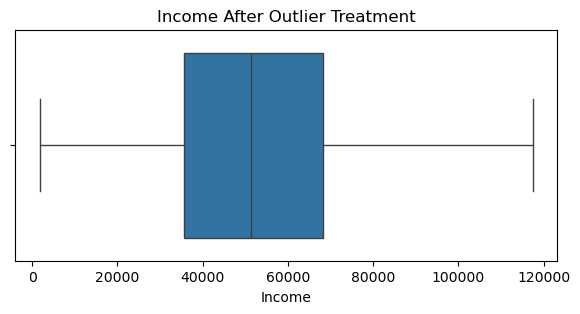

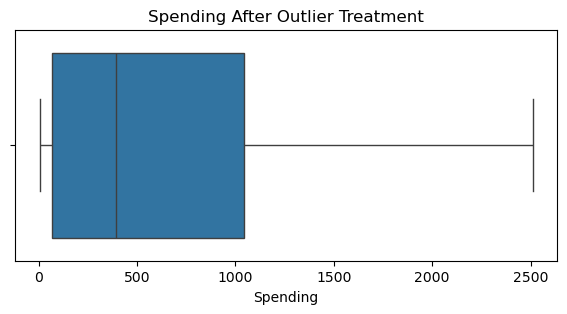

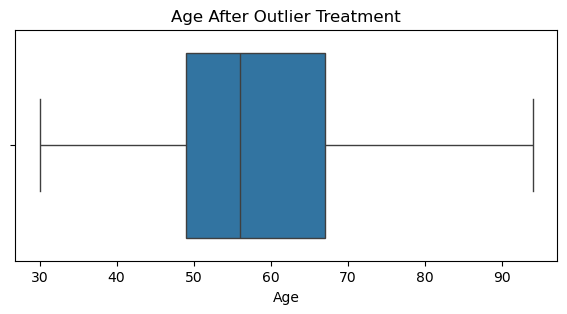

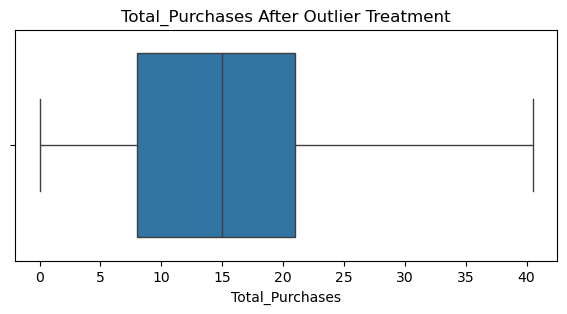

In [20]:
#• Perform outlier treatment by capping the outliers to the upper and lower limits



def cap_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[column] = np.clip(df[column], lower, upper)

for col in ["Income", "Spending", "Age", "Total_Purchases"]:
    cap_outliers(data, col)


#cheking result
num_cols = ["Income", "Spending", "Age", "Total_Purchases"]

for col in num_cols:
    plt.figure(figsize=(7,3))
    sns.boxplot(x=data[col])
    plt.title(f"{col} After Outlier Treatment")
    plt.show()


#interpretation:The outliers were treated using the IQR method. Extreme values outside the lower and upper limits were capped 
#              using numpy.clip(). The updated box plots show fewer extreme values while preserving all customer records for further analysis.


In [16]:
#6. Encoding 
#• Use ordinal encoding for the education column

education_order = {
    "Basic": 1,
    "2n Cycle": 2,
    "Graduation": 3,
    "Master": 4,
    "PhD": 5
}

data["Education_Encoded"] = data["Education"].map(education_order)

In [17]:
#• Use one-hot encoding for the country and marital_status columns

data_encoded = pd.get_dummies(
    data,
    columns=["Country", "Marital_Status"],
    drop_first=True
)

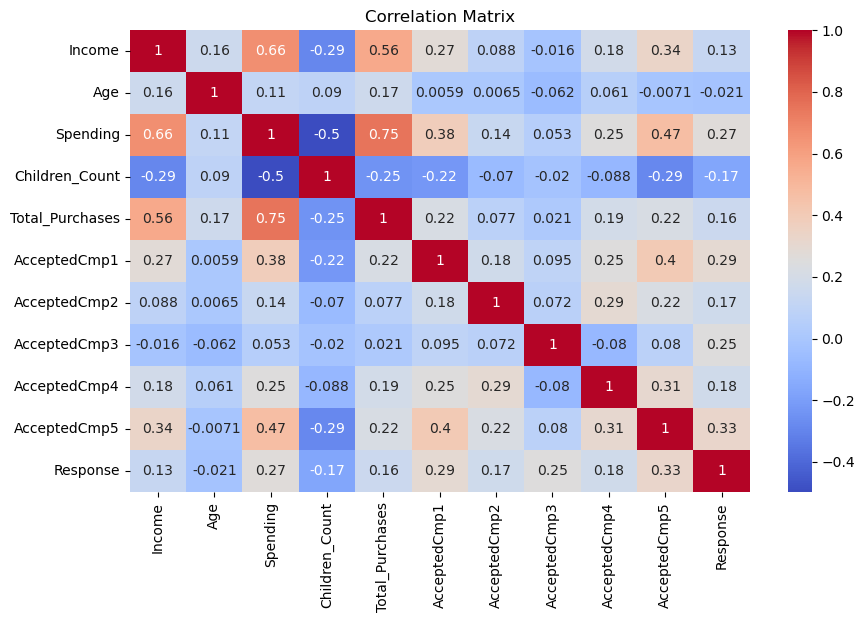

In [18]:
#7. Correlation Analysis
#• Select a subset of columns for correlation analysis
#• Compute the correlation matrix (new_data[var_cor].corr()) and plot a heatmap (sns.heatmap())
var_cor = [
    "Income",
    "Age",
    "Spending",
    "Children_Count",
    "Total_Purchases",
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

corr = data[var_cor].corr()

plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [20]:
#8. Hypothesis Testing
#• Define and test hypotheses related to customer behavior using statistical tests (stats.ttest_ind())

#Hypothesis 1: Customers who accepted the last campaign spend more
accepted = data[data["Response"] == 1]["Spending"]
not_accepted = data[data["Response"] == 0]["Spending"]

stats.ttest_ind(accepted, not_accepted, equal_var=False)


#INTERPRETATION
#.  Since the p-value is less than 0.05, we reject the null hypothesis. Customers who accepted the last campaign have significantly different
#   spending behavior compared to those who did not.

TtestResult(statistic=np.float64(10.850260851596694), pvalue=np.float64(3.003309126742805e-24), df=np.float64(404.88206655368276))

In [23]:
#Hypothesis 2: Customers with children spend differently

with_children= data[data["Has_Children"]== 1]["Spending"]
without_children= data[data["Has_Children"]== 0]["Spending"]

stats.ttest_ind(with_children,without_children, equal_var=False)

#INTERPRETATION
 #.Since the p-value is less than 0.05, customers with children and customers without children have significantly different spending patterns.


TtestResult(statistic=np.float64(-25.070857788085302), pvalue=np.float64(1.7777029556420493e-105), df=np.float64(894.2443128612329))

In [24]:
#Hypothesis 3: Campaign responders have different income

income_accepted = data[data["Response"] == 1]["Income"]
income_not_accepted = data[data["Response"] == 0]["Income"]

stats.ttest_ind(income_accepted, income_not_accepted, equal_var=False)


#INTERPRETATION
#            Since the p-value is less than 0.05, income is significantly different between customers who accepted and 
#.           those who did not accept the campaign.

TtestResult(statistic=np.float64(6.718847894114681), pvalue=np.float64(5.194420642802332e-11), df=np.float64(480.66385791176157))

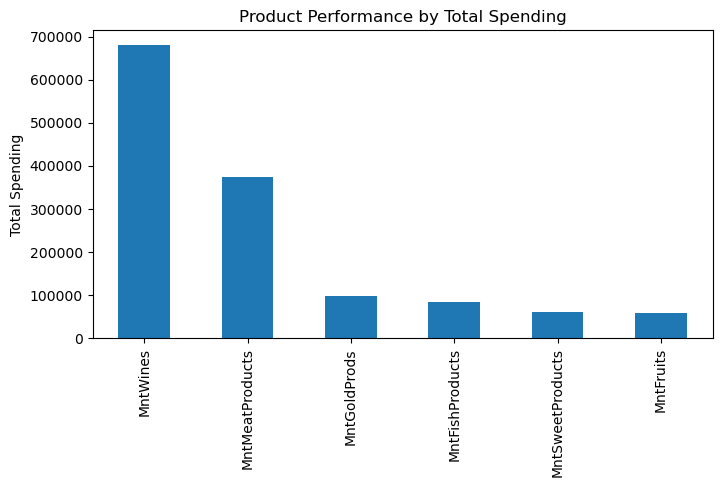

In [25]:
#9. Visualization
 #• Visualize the performance of products (prod_data) using a bar plot

prod_data = data[
    [
        "MntWines",
        "MntFruits",
        "MntMeatProducts",
        "MntFishProducts",
        "MntSweetProducts",
        "MntGoldProds"
    ]
].sum().sort_values(ascending=False)

prod_data.plot(kind="bar", figsize=(8,4))
plt.title("Product Performance by Total Spending")
plt.ylabel("Total Spending")
plt.show()



#Insight: Wine products generated the highest spending, followed by meat products.

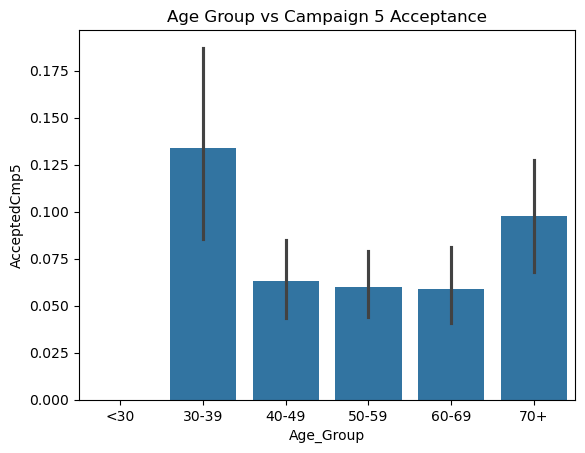

In [26]:
#• Explore the relationship between age and campaign acceptance rate (acceptedcmp5) using a bar plot
 #Age and campaign acceptance
data["Age_Group"] = pd.cut(
    data["Age"],
    bins=[0, 30, 40, 50, 60, 70, 200],
    labels=["<30", "30-39", "40-49", "50-59", "60-69", "70+"]
)

sns.barplot(x="Age_Group", y="AcceptedCmp5", data=data)
plt.title("Age Group vs Campaign 5 Acceptance")
plt.show()

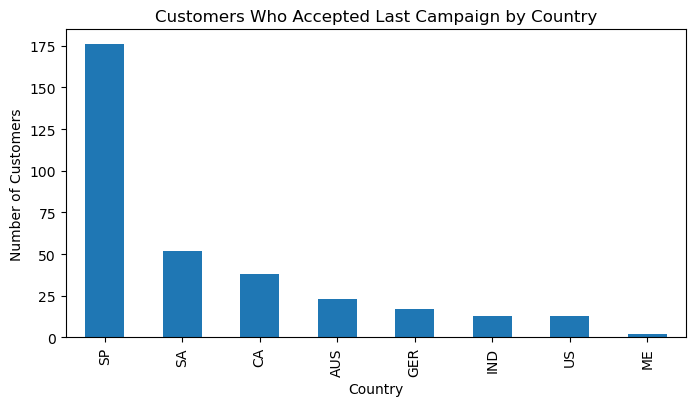

In [27]:
#• Determine the country with the most customers who accepted the last campaign using a bar plot
 #Country with most accepted last campaign

country_response = data[data["Response"] == 1]["Country"].value_counts()

country_response.plot(kind="bar", figsize=(8,4))
plt.title("Customers Who Accepted Last Campaign by Country")
plt.ylabel("Number of Customers")
plt.show()

#Insight:
#       Spain (SP) has the highest number of customers who accepted the last campaign.

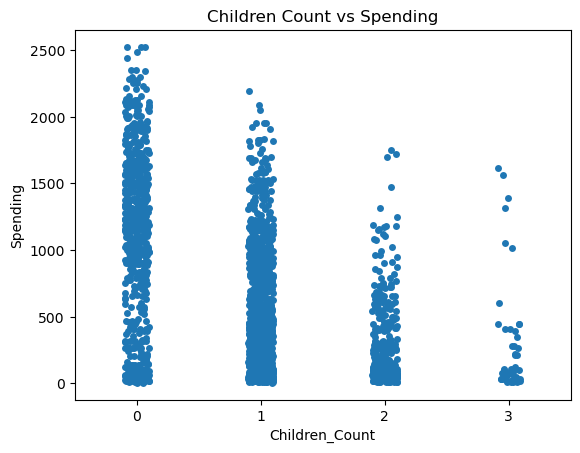

In [28]:
#• Analyze the relationship between children_count and spending using a strip plot

sns.stripplot(x="Children_Count", y="Spending", data=data)
plt.title("Children Count vs Spending")
plt.show()

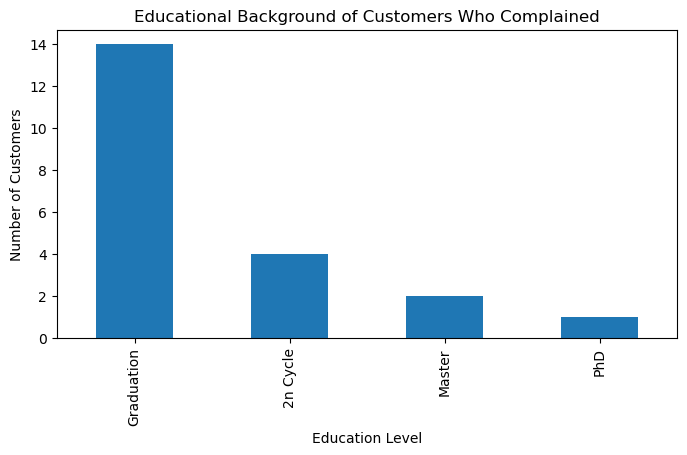

In [29]:
#Visualize the educational background of customers who complained in the last two years using a bar plot

complaints = data[data["Complain"] == 1]

education_counts = complaints["Education"].value_counts()

education_counts.plot(kind="bar", figsize=(8,4))

plt.title("Educational Background of Customers Who Complained")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")

plt.show()

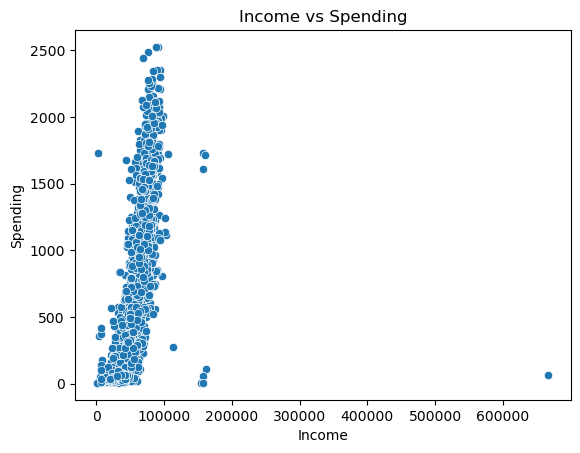

In [30]:
#Explore the relationship between income and spending using a scatter plot

sns.scatterplot(x="Income", y="Spending", data=data)
plt.title("Income vs Spending")
plt.show()

#insight:The scatter plot shows a positive relationship between income and spending. Customers with higher incomes generally tend to 
#.       spend more, although there is considerable variation and a few outliers.